# TensorBoard 可视化 - 新的 200k Steps 训练结果 (Minigrid)

本 notebook 用于可视化新的 Minigrid 训练结果：
- PPO+NS (Minigrid): PPO_10 (200,000 steps)
- PPO+BANS (Minigrid): PPO_8 (200,000 steps)


In [13]:
# ==== 基础依赖 ====
import os
from tensorboard.backend.event_processing import event_accumulator
import matplotlib.pyplot as plt
import numpy as np

%matplotlib inline

# 使用 seaborn style（如果可用）
try:
    plt.style.use("seaborn-v0_8")
except:
    try:
        plt.style.use("seaborn")
    except:
        pass

# ==== 自动检测项目根目录 ====
PROJECT_ROOT = os.path.dirname(os.path.abspath(""))
LOGS_DIR = os.path.join(PROJECT_ROOT, "boundary_ns_rl", "logs")

# ==== 辅助函数：从 TensorBoard 加载数据 ====
def load_scalar_from_event(run_dir, tag, silent=False):
    """从 TensorBoard run 目录中读取指定 tag 的 scalar 序列"""
    if not os.path.isdir(run_dir):
        if not silent:
            print(f"[WARN] Run dir not found: {run_dir}")
        return None, None
    
    ea = event_accumulator.EventAccumulator(
        run_dir,
        size_guidance={"scalars": 0}
    )
    ea.Reload()
    
    available = ea.Tags().get("scalars", [])
    if tag not in available:
        if not silent:
            print(f"[WARN] tag '{tag}' not found in {run_dir}")
        return None, None
    
    events = ea.Scalars(tag)
    steps = np.array([e.step for e in events])
    values = np.array([e.value for e in events])
    return steps, values

def load_tensorboard_data(tensorboard_dir, name, total_training_steps=200000):
    """从 TensorBoard 目录加载数据并转换为统一的格式"""
    if not os.path.isdir(tensorboard_dir):
        print(f"  ✗ 未找到 {name} TensorBoard 日志: {tensorboard_dir}")
        return None
    
    print(f"\n  ✓ 找到 {name} TensorBoard 日志: {tensorboard_dir}")
    
    # 加载各种指标
    external_steps, external_vals = load_scalar_from_event(tensorboard_dir, "rollout/episode_external_reward", silent=True)
    intrinsic_steps, intrinsic_vals = load_scalar_from_event(tensorboard_dir, "rollout/episode_intrinsic_reward", silent=True)
    total_steps, total_vals = load_scalar_from_event(tensorboard_dir, "rollout/total_reward_cumulative", silent=True)
    
    if external_vals is None or len(external_vals) == 0:
        print(f"  ✗ 无法加载 {name} 数据: 未找到有效的 episode_external_reward")
        return None
    
    # 将 TensorBoard 数据转换为统一的格式
    tb_data = {
        "episode_rewards": external_vals,
        "episode_intrinsic": intrinsic_vals if intrinsic_vals is not None and len(intrinsic_vals) > 0 else np.zeros_like(external_vals),
        "episode_lengths": None,
        "all_step_rewards": None,
    }
    
    # 关键：将 episode 数据转换为 step 数据
    if external_steps is not None and len(external_steps) > 0:
        # 计算每个 episode 的长度
        episode_lengths = np.diff(external_steps, prepend=0)
        if len(external_steps) > 0:
            episode_lengths[0] = external_steps[0] + 1
        
        # 创建 step-level 的 rewards 数组
        step_rewards = np.zeros(total_training_steps)
        step_intrinsic = np.zeros(total_training_steps)
        
        # 将每个 episode 的 reward 分配到对应的 steps
        current_step = 0
        for i in range(len(external_vals)):
            ep_length = int(episode_lengths[i])
            if current_step >= total_training_steps:
                break
            end_step = min(current_step + ep_length, total_training_steps)
            actual_length = end_step - current_step
            
            if actual_length > 0:
                # 将 episode reward 平均分配到该 episode 的所有 steps
                step_rewards[current_step:end_step] = external_vals[i] / actual_length
                if intrinsic_vals is not None and i < len(intrinsic_vals):
                    step_intrinsic[current_step:end_step] = intrinsic_vals[i] / actual_length
            
            current_step = end_step
        
        tb_data["all_step_rewards"] = step_rewards
        tb_data["step_intrinsic"] = step_intrinsic
        tb_data["Total Rewards"] = np.cumsum(step_rewards)
    else:
        # 如果没有 step 信息，使用简单的方法
        n_episodes = len(external_vals)
        if n_episodes > 0:
            steps_per_episode = total_training_steps // n_episodes
            step_rewards = np.zeros(total_training_steps)
            step_intrinsic = np.zeros(total_training_steps)
            
            for i in range(n_episodes):
                start_step = i * steps_per_episode
                end_step = min((i + 1) * steps_per_episode, total_training_steps)
                if end_step > start_step:
                    step_rewards[start_step:end_step] = external_vals[i] / (end_step - start_step)
                    if intrinsic_vals is not None and i < len(intrinsic_vals):
                        step_intrinsic[start_step:end_step] = intrinsic_vals[i] / (end_step - start_step)
            
            tb_data["all_step_rewards"] = step_rewards
            tb_data["step_intrinsic"] = step_intrinsic
            tb_data["Total Rewards"] = np.cumsum(step_rewards)
        else:
            tb_data["all_step_rewards"] = np.zeros(total_training_steps)
            tb_data["step_intrinsic"] = np.zeros(total_training_steps)
            tb_data["Total Rewards"] = np.zeros(total_training_steps)
    
    print(f"    - Episode External Rewards: {len(external_vals)} 个数据点")
    print(f"    - Step Rewards: {len(tb_data['all_step_rewards'])} 个数据点")
    if intrinsic_vals is not None and len(intrinsic_vals) > 0:
        print(f"    - Episode Intrinsic Rewards: {len(intrinsic_vals)} 个数据点")
    
    return tb_data

# ==== 加载新的训练结果 ====
DATA = {}

# 加载 PPO+NS (Minigrid) - PPO_10
NS_TENSORBOARD_DIR = os.path.join(LOGS_DIR, "minigrid_ppo_ns", "PPO_10")
ns_data = load_tensorboard_data(NS_TENSORBOARD_DIR, "PPO+Novelty Search (Minigrid)", total_training_steps=200000)
if ns_data is not None:
    DATA["PPO+Novelty Search (Minigrid)"] = ns_data
    print(f"  ✓ 成功加载: PPO+NS (Minigrid)")

# 加载 PPO+BANS (Minigrid) - PPO_8
BANS_TENSORBOARD_DIR = os.path.join(LOGS_DIR, "minigrid_ppo_bans", "PPO_8")
bans_data = load_tensorboard_data(BANS_TENSORBOARD_DIR, "PPO+Boundary-Aware Novelty Search (Minigrid)", total_training_steps=200000)
if bans_data is not None:
    DATA["PPO+Boundary-Aware Novelty Search (Minigrid)"] = bans_data
    print(f"  ✓ 成功加载: PPO+BANS (Minigrid)")

print(f"\n总共加载 {len(DATA)} 个数据集: {', '.join(DATA.keys())}")



  ✓ 找到 PPO+Novelty Search (Minigrid) TensorBoard 日志: /Users/songxiaodao/Desktop/CSE 5100/Project/CSE5100-Project/boundary_ns_rl/logs/minigrid_ppo_ns/PPO_10
    - Episode External Rewards: 117 个数据点
    - Step Rewards: 200000 个数据点
    - Episode Intrinsic Rewards: 117 个数据点
  ✓ 成功加载: PPO+NS (Minigrid)

  ✓ 找到 PPO+Boundary-Aware Novelty Search (Minigrid) TensorBoard 日志: /Users/songxiaodao/Desktop/CSE 5100/Project/CSE5100-Project/boundary_ns_rl/logs/minigrid_ppo_bans/PPO_8
    - Episode External Rewards: 118 个数据点
    - Step Rewards: 200000 个数据点
    - Episode Intrinsic Rewards: 118 个数据点
  ✓ 成功加载: PPO+BANS (Minigrid)

总共加载 2 个数据集: PPO+Novelty Search (Minigrid), PPO+Boundary-Aware Novelty Search (Minigrid)


In [14]:
# ===== 查看数据字段 =====
if len(DATA) > 0:
    print("各数据集包含的字段:")
    print("-" * 60)
    for name, data in DATA.items():
        print(f"\n{name}:")
        for key in sorted(data.keys()):
            value = data[key]
            if isinstance(value, np.ndarray):
                print(f"  - {key}: shape={value.shape}")
            else:
                print(f"  - {key}: {type(value).__name__}")
    print("-" * 60)


各数据集包含的字段:
------------------------------------------------------------

PPO+Novelty Search (Minigrid):
  - Total Rewards: shape=(200000,)
  - all_step_rewards: shape=(200000,)
  - episode_intrinsic: shape=(117,)
  - episode_lengths: NoneType
  - episode_rewards: shape=(117,)
  - step_intrinsic: shape=(200000,)

PPO+Boundary-Aware Novelty Search (Minigrid):
  - Total Rewards: shape=(200000,)
  - all_step_rewards: shape=(200000,)
  - episode_intrinsic: shape=(118,)
  - episode_lengths: NoneType
  - episode_rewards: shape=(118,)
  - step_intrinsic: shape=(200000,)
------------------------------------------------------------



绘制对比图: PPO+Novelty Search (Minigrid), PPO+Boundary-Aware Novelty Search (Minigrid)

绘制 Episode External Rewards...


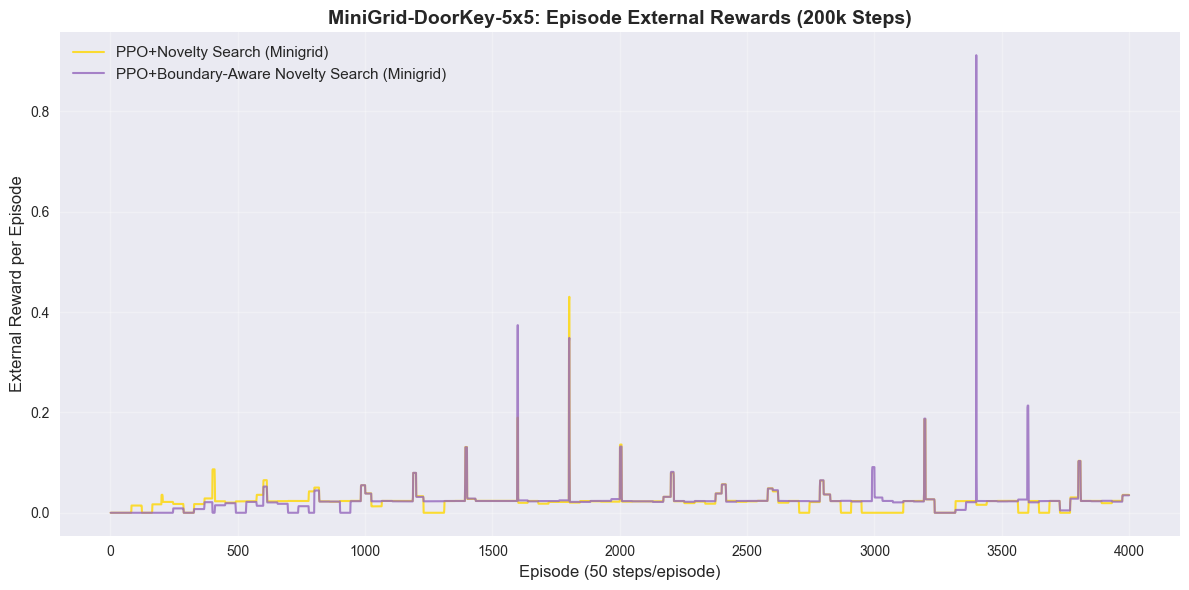


绘制 Episode Intrinsic Rewards...


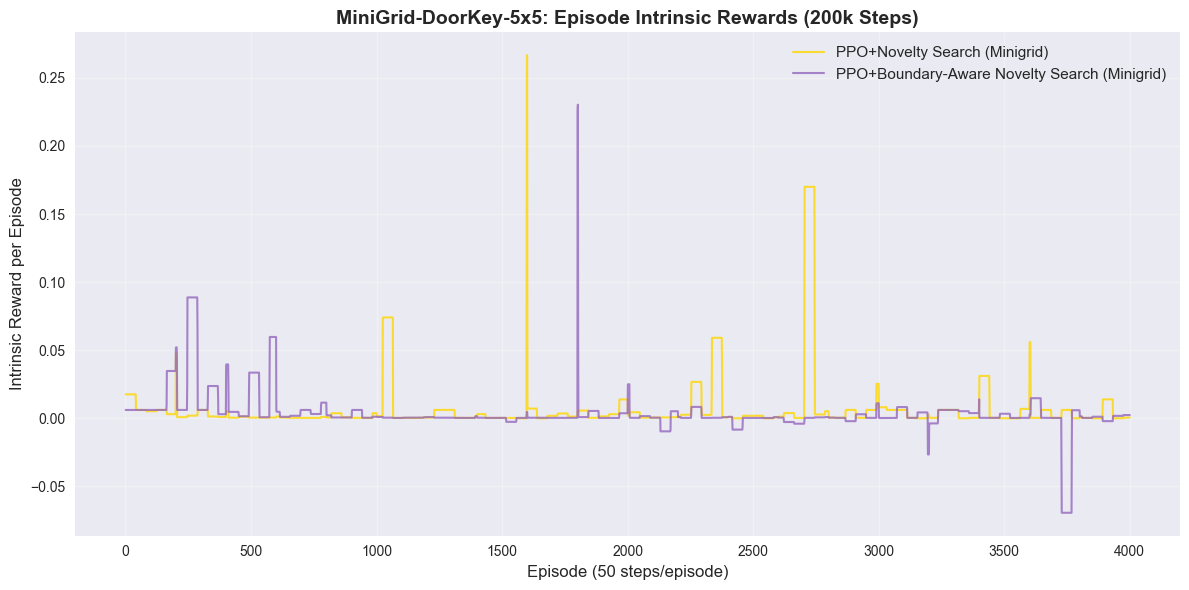


绘制 Total Reward (Cumulative)...
  [OK] PPO+Novelty Search (Minigrid): 4000 个 episodes
  [OK] PPO+Boundary-Aware Novelty Search (Minigrid): 4000 个 episodes


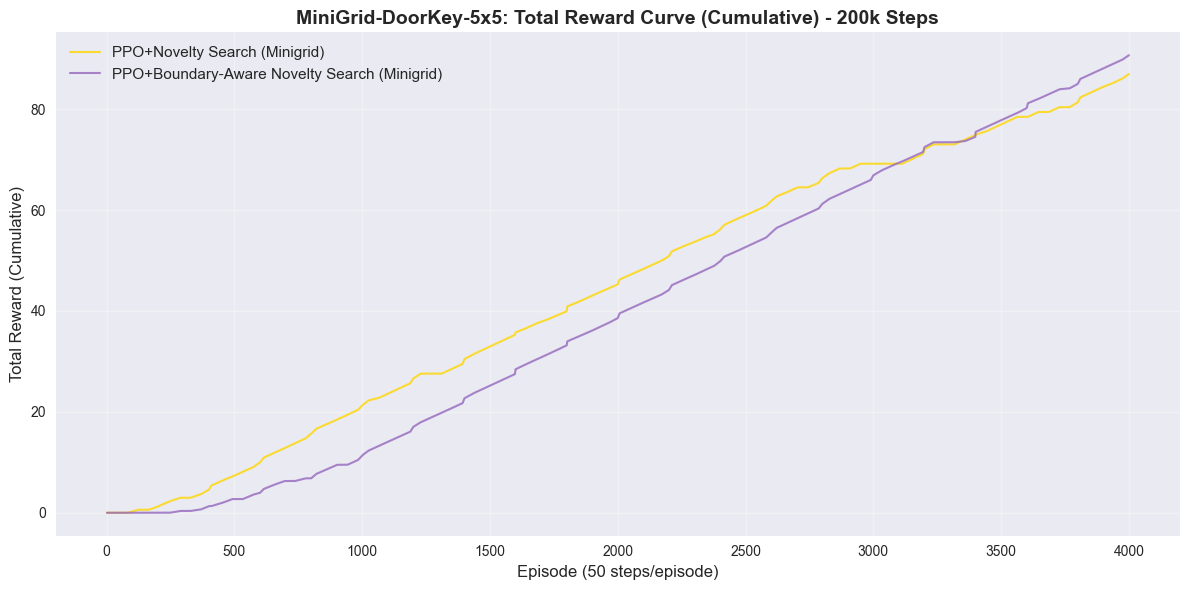

In [15]:
# ===== 绘制对比图 =====
# 固定颜色映射
color_map = {
    "PPO+Novelty Search (Minigrid)": "gold",
    "PPO+Boundary-Aware Novelty Search (Minigrid)": "tab:purple",
}

def get_data_field(data_dict, field_name, default=None):
    """从数据字典中获取指定字段"""
    if field_name in data_dict:
        return data_dict[field_name]
    alternatives = {
        "step_rewards": ["all_step_rewards", "rewarded_steps", "step_rewards"],
    }
    if field_name in alternatives:
        for alt in alternatives[field_name]:
            if alt in data_dict:
                return data_dict[alt]
    return default

def convert_steps_to_episodes(step_data, steps_per_episode=50):
    """将 step-level 数据转换为固定大小的 episode 数据"""
    if not isinstance(step_data, np.ndarray):
        step_data = np.array(step_data)
    n_steps = len(step_data)
    n_episodes = n_steps // steps_per_episode
    episode_data = []
    for i in range(n_episodes):
        start_idx = i * steps_per_episode
        end_idx = min((i + 1) * steps_per_episode, n_steps)
        episode_reward = np.sum(step_data[start_idx:end_idx])
        episode_data.append(episode_reward)
    return np.array(episode_data)

if len(DATA) > 0:
    print("\n" + "=" * 60)
    print(f"绘制对比图: {', '.join(DATA.keys())}")
    print("=" * 60)
    
    # 1. 绘制 Episode External Rewards
    print(f"\n绘制 Episode External Rewards...")
    plt.figure(figsize=(12, 6))
    for name, data in DATA.items():
        step_rewards = get_data_field(data, "step_rewards")
        if step_rewards is None:
            print(f"  [WARN] {name} 中没有找到 step_rewards 字段")
            continue
        if not isinstance(step_rewards, np.ndarray):
            step_rewards = np.array(step_rewards)
        
        episode_rewards = convert_steps_to_episodes(step_rewards, steps_per_episode=50)
        x_data = np.arange(1, len(episode_rewards) + 1)
        color = color_map.get(name, None)
        plt.plot(x_data, episode_rewards, label=name, linewidth=1.5, alpha=0.8, color=color)
    plt.legend(fontsize=11)
    plt.grid(True, alpha=0.3)
    plt.xlabel("Episode (50 steps/episode)", fontsize=12)
    plt.ylabel("External Reward per Episode", fontsize=12)
    plt.title("MiniGrid-DoorKey-5x5: Episode External Rewards (200k Steps)", fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()
    
    # 2. 绘制 Episode Intrinsic Rewards
    print(f"\n绘制 Episode Intrinsic Rewards...")
    plt.figure(figsize=(12, 6))
    for name, data in DATA.items():
        if "step_intrinsic" in data:
            step_intrinsic = data["step_intrinsic"]
        else:
            step_intrinsic = np.zeros(len(data.get("all_step_rewards", [0])))
        
        if not isinstance(step_intrinsic, np.ndarray):
            step_intrinsic = np.array(step_intrinsic)
        
        episode_intrinsic = convert_steps_to_episodes(step_intrinsic, steps_per_episode=50)
        x_data = np.arange(1, len(episode_intrinsic) + 1)
        color = color_map.get(name, None)
        plt.plot(x_data, episode_intrinsic, label=name, linewidth=1.5, alpha=0.8, color=color)
    plt.legend(fontsize=11)
    plt.grid(True, alpha=0.3)
    plt.xlabel("Episode (50 steps/episode)", fontsize=12)
    plt.ylabel("Intrinsic Reward per Episode", fontsize=12)
    plt.title("MiniGrid-DoorKey-5x5: Episode Intrinsic Rewards (200k Steps)", fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()
    
    # 3. 绘制累积总奖励曲线
    print(f"\n绘制 Total Reward (Cumulative)...")
    plt.figure(figsize=(12, 6))
    for name, data in DATA.items():
        step_rewards = get_data_field(data, "step_rewards")
        if step_rewards is None:
            print(f"  [WARN] {name} 中没有找到 step_rewards 字段")
            continue
        if not isinstance(step_rewards, np.ndarray):
            step_rewards = np.array(step_rewards)
        
        episode_rewards = convert_steps_to_episodes(step_rewards, steps_per_episode=50)
        total_reward_curve = np.cumsum(episode_rewards)
        x_data = np.arange(1, len(total_reward_curve) + 1)
        
        color = color_map.get(name, None)
        plt.plot(x_data, total_reward_curve, label=name, linewidth=1.5, alpha=0.8, color=color)
        print(f"  [OK] {name}: {len(total_reward_curve)} 个 episodes")
    
    plt.legend(fontsize=11)
    plt.grid(True, alpha=0.3)
    plt.xlabel("Episode (50 steps/episode)", fontsize=12)
    plt.ylabel("Total Reward (Cumulative)", fontsize=12)
    plt.title("MiniGrid-DoorKey-5x5: Total Reward Curve (Cumulative) - 200k Steps", fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()
    
else:
    print("\n未找到任何可用的数据")
